# Донавчання YOLOv9-c на CUBIT-InSeg

Модель після попередніх 35 епох використовується як початкові ваги.
Вже підготовлений датасет `cubit_1280` повторно не обробляється.

Далі модель донавчається ще 35 епох, після чого виконується оцінювання
на validation та test вибірках.


In [1]:
!pip -q install ultralytics

import shutil
from pathlib import Path

import yaml
import pandas as pd
import matplotlib.pyplot as plt
import torch

from IPython.display import display
from ultralytics import YOLO

print("Ultralytics:", __import__("ultralytics").__version__)
print("PyTorch:", torch.__version__)

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.5/46.5 kB 3.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 57.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 78.4/78.4 kB 5.1 MB/s eta 0:00:00
Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Ultralytics: 8.4.155
PyTorch: 2.10.0+cu128


## 1. Перевірка готових даних і вагів


In [2]:
BASE = Path("/kaggle/input/notebooks/darrriax/cubit-inseg-experiment")

BEST_PT = BASE / "yolov9c_cubit_best.pt"
DATASET = BASE / "cubit_1280"

print("BASE:", BASE)
print("BEST:", BEST_PT)
print("DATASET:", DATASET)

assert BASE.exists(), f"Не знайдено: {BASE}"
assert BEST_PT.exists(), f"Не знайдено best.pt: {BEST_PT}"
assert DATASET.exists(), f"Не знайдено cubit_1280: {DATASET}"

for split in ["train", "val", "test"]:
    images = DATASET / split / "images"
    labels = DATASET / split / "labels"
    n_images = len(list(images.glob("*")))
    n_labels = len(list(labels.glob("*.txt")))
    print(f"{split:5s}: images={n_images}, labels={n_labels}")

print("\nBest model:")
print(f"  {BEST_PT}")
print(f"  size = {BEST_PT.stat().st_size / 1024**2:.1f} MB")

BASE: /kaggle/input/notebooks/darrriax/cubit-inseg-experiment
BEST: /kaggle/input/notebooks/darrriax/cubit-inseg-experiment/yolov9c_cubit_best.pt
DATASET: /kaggle/input/notebooks/darrriax/cubit-inseg-experiment/cubit_1280
train: images=5596, labels=5596
val  : images=699, labels=699
test : images=701, labels=701

Best model:
  /kaggle/input/notebooks/darrriax/cubit-inseg-experiment/yolov9c_cubit_best.pt
  size = 53.8 MB


## 2. Створення конфігурації датасету

Для нового запуску створюється YAML-файл з актуальним шляхом
до вже підготовленого датасету `cubit_1280`.
Класи беруться зі старого `cubit.yaml`, щоб зберегти ту саму
відповідність `0 — crack`, `1 — spalling`.


In [3]:
old_yaml_path = DATASET / "cubit.yaml"
yaml_path = Path("/kaggle/working/cubit_finetune.yaml")

old_config = yaml.safe_load(old_yaml_path.read_text())

print("Класи з попереднього датасету:")
print(old_config["names"])

data_config = {
    "path": str(DATASET),
    "train": "train/images",
    "val": "val/images",
    "test": "test/images",
    "names": old_config["names"],
    "nc": old_config["nc"],
}

yaml_path.write_text(
    yaml.dump(data_config, allow_unicode=True, sort_keys=False)
)

print("\nНовий YAML:")
print(yaml_path.read_text())

Класи з попереднього датасету:
{0: 'crack', 1: 'spalling'}

Новий YAML:
path: /kaggle/input/notebooks/darrriax/cubit-inseg-experiment/cubit_1280
train: train/images
val: val/images
test: test/images
names:
  0: crack
  1: spalling
nc: 2



## 3. Донавчання моделі

Початкові ваги — `yolov9c_cubit_best.pt` після перших 35 епох.
Це новий етап (`resume=False`): стан оптимізатора в збереженому
чекпоінті відсутній, тому відновити той самий training run неможливо.

Гіперпараметри ті самі, що на першому етапі (AdamW, lr0=0.001,
warmup 3 епохи, flipud/fliplr=0.5), щоб другі 35 епох були
максимально близькими до продовження експерименту.


In [4]:
model = YOLO(str(BEST_PT))

results = model.train(
    data=str(yaml_path),
    epochs=35,
    imgsz=1280,
    batch=2,
    device=0,
    workers=2,
    seed=42,
    optimizer="AdamW",
    lr0=0.001,
    lrf=0.01,
    weight_decay=0.0005,
    warmup_epochs=3.0,
    patience=15,
    amp=True,
    cache=False,
    project="/kaggle/working/runs",
    name="yolov9c_cubit_finetune35",
    exist_ok=True,
    resume=False,
    fliplr=0.5,
    flipud=0.5,
    hsv_h=0.01,
    hsv_s=0.4,
    hsv_v=0.3,
    degrees=0.0,
    translate=0.05,
    scale=0.1,
    shear=0.0,
    perspective=0.0,
    mosaic=0.0,
    mixup=0.0,
    copy_paste=0.0,
    erasing=0.0,
)

print("Навчання завершено.")
print("Результати:", results.save_dir)

Ultralytics 8.4.155 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=2, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/cubit_finetune.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=35, erasing=0.0, exist_ok=True, fliplr=0.5, flipud=0.5, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.01, hsv_s=0.4, hsv_v=0.3, imgsz=1280, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=/kaggle/input/notebooks/darrriax/cubit-inseg-experiment/yolov9c_cubit_best.pt, momentum=0.937, mosaic=0

/usr/local/lib/python3.12/dist-packages/ray/train/_internal/session.py:676: UserWarning: `get_trial_id` is meant to only be called inside a function that is executed by a Tuner or Trainer. Returning `None`.
  warnings.warn(


       2/35      7.28G     0.6621     0.7596     0.5329      0.925          0          4       1280: 100% ━━━━━━━━━━━━ 2798/2798 2.7it/s 17:28
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 175/175 3.1it/s 56.5s
                   all        699       6135      0.599      0.688      0.583      0.495       0.58      0.665      0.561      0.433

      Epoch    GPU_mem   box_loss   seg_loss   cls_loss   dfl_loss   sem_loss  Instances       Size
       3/35      7.91G     0.6866     0.7608     0.5514      0.935          0         38       1280: 100% ━━━━━━━━━━━━ 2798/2798 2.7it/s 17:25
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 175/175 3.1it/s 56.5s
                   all        699       6135      0.755      0.762      0.704       0.57      0.719      0.729      0.655      0.447

## 4. Результати донавчання

Аналізуються метрики другого етапу навчання та їхня динаміка.

На графіку додатково відображено порогове значення Mask mAP@0.5 = 0,75,
встановлене у функціональних вимогах до системи.


,epoch,time,train/box_loss,train/seg_loss,train/cls_loss,train/dfl_loss,train/sem_loss,metrics/precision(B),metrics/recall(B),metrics/mAP50(B),...,metrics/mAP50(M),metrics/mAP50-95(M),val/box_loss,val/seg_loss,val/cls_loss,val/dfl_loss,val/sem_loss,lr/pg0,lr/pg1,lr/pg2
25,26,28661.4,0.42044,0.52908,0.28968,0.81084,0,0.85545,0.80587,0.79358,...,0.74593,0.53813,0.51201,0.61430,1.15635,0.88752,0,0.000293,0.000293,0.000293
26,27,29764.7,0.40896,0.53045,0.28391,0.81064,0,0.83911,0.78679,0.76966,...,0.72023,0.52352,0.52082,0.60526,1.55399,0.89938,0,0.000265,0.000265,0.000265
27,28,30868.2,0.40218,0.51569,0.27571,0.80537,0,0.85210,0.79146,0.77226,...,0.72932,0.53056,0.50892,0.60189,1.70916,0.89445,0,0.000236,0.000236,0.000236
28,29,31970.7,0.38981,0.50718,0.26623,0.80083,0,0.83954,0.81144,0.78034,...,0.73305,0.53430,0.47736,0.58011,1.52752,0.87873,0,0.000208,0.000208,0.000208
29,30,33074.1,0.38503,0.50035,0.26517,0.79876,0,0.84829,0.82036,0.79357,...,0.75067,0.53967,0.46222,0.57618,1.74654,0.86811,0,0.000180,0.000180,0.000180
30,31,34177.2,0.37197,0.48873,0.25455,0.79539,0,0.84837,0.79997,0.78330,...,0.73606,0.53559,0.47961,0.58443,1.67253,0.88389,0,0.000151,0.000151,0.000151
31,32,35280.7,0.37178,0.49043,0.25510,0.79621,0,0.85235,0.80265,0.77790,...,0.73183,0.53299,0.47895,0.57621,1.68590,0.88400,0,0.000123,0.000123,0.000123
32,33,36383.5,0.35894,0.47635,0.24663,0.79477,0,0.85091,0.81314,0.79685,...,0.75044,0.54624,0.46600,0.56886,1.48947,0.87872,0,0.000095,0.000095,0.000095
33,34,37486.4,0.35818,0.47829,0.24478,0.79272,0,0.87046,0.81110,0.80259,...,0.75393,0.54556,0.45718,0.56755,1.38623,0.87352,0,0.000067,0.000067,0.000067
34,35,38589.4,0.34630,0.46645,0.23668,0.78995,0,0.86809,0.81004,0.80052,...,0.75459,0.54704,0.45751,0.56498,1.44006,0.87546,0,0.000038,0.000038,0.000038


Кількість епох: 35

Найкращі значення:
metrics/mAP50(M): 0.7638
metrics/mAP50-95(M): 0.5470
metrics/precision(M): 0.8347
metrics/recall(M): 0.7844


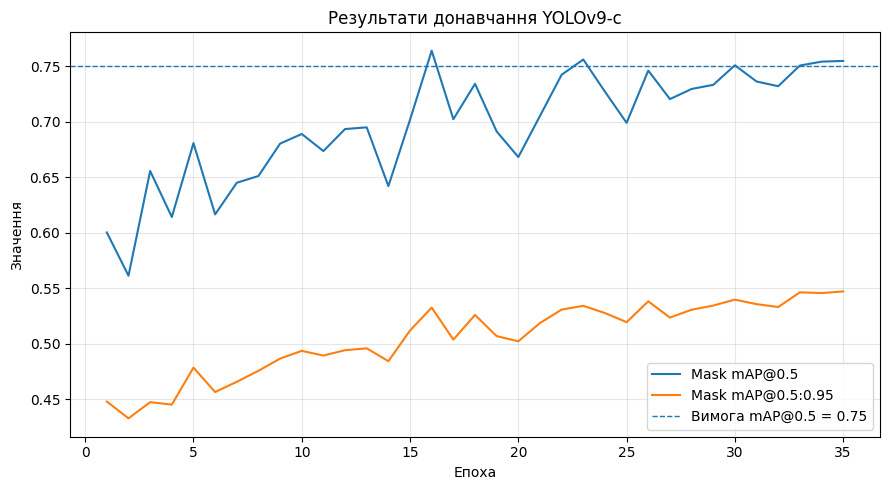

In [5]:
run_dir = Path("/kaggle/working/runs/yolov9c_cubit_finetune35")
results_csv = run_dir / "results.csv"

assert results_csv.exists(), f"Не знайдено {results_csv}"

df = pd.read_csv(results_csv)
df.columns = [c.strip() for c in df.columns]

display(df.tail(10))

print("Кількість епох:", len(df))
print("\nНайкращі значення:")

for col in [
    "metrics/mAP50(M)",
    "metrics/mAP50-95(M)",
    "metrics/precision(M)",
    "metrics/recall(M)",
]:
    if col in df.columns:
        print(f"{col}: {df[col].max():.4f}")

epoch_col = "epoch"

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(df[epoch_col], df["metrics/mAP50(M)"], label="Mask mAP@0.5")
ax.plot(df[epoch_col], df["metrics/mAP50-95(M)"], label="Mask mAP@0.5:0.95")
ax.axhline(0.75, linestyle="--", linewidth=1, label="Вимога mAP@0.5 = 0.75")
ax.set_xlabel("Епоха")
ax.set_ylabel("Значення")
ax.set_title("Результати донавчання YOLOv9-c")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("/kaggle/working/finetune_curves.png", dpi=140)
plt.show()

## 5. Фінальне оцінювання моделі

Найкраща модель другого етапу перевіряється окремо
на validation та test вибірках.


In [6]:
best_pt = run_dir / "weights" / "best.pt"

assert best_pt.exists(), f"Не знайдено: {best_pt}"

trained = YOLO(str(best_pt))

print("========== VALIDATION ==========")
val_results = trained.val(
    data=str(yaml_path),
    split="val",
    imgsz=1280,
    batch=2,
    device=0,
)

print("\n========== TEST ==========")
test_results = trained.val(
    data=str(yaml_path),
    split="test",
    imgsz=1280,
    batch=2,
    device=0,
)

========== VALIDATION ==========
Ultralytics 8.4.155 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
YOLOv9c-seg summary (fused): 169 layers, 27,626,070 parameters, 0 gradients, 147.6 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 232.2±78.7 MB/s, size: 192.0 KB)
val: Scanning /kaggle/input/notebooks/darrriax/cubit-inseg-experiment/cubit_1280/val/labels... 699 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 699/699 150.4it/s 4.6s
WARNING ⚠️ val: Cache directory /kaggle/input/notebooks/darrriax/cubit-inseg-experiment/cubit_1280/val is not writable, cache not saved.
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 350/350 2.6it/s 2:15
                   all        699       6135      0.875      0.813      0.807      0.709      0.829      0.776       0.75      0.539
                 crack        299       5029      0.814      0.644      0.664      0.502     

## 6. Збереження результатів

Найкраща та остання моделі зберігаються в `/kaggle/working`
для подальшого використання та завантаження з Output.


In [7]:
final_best = run_dir / "weights" / "best.pt"
final_last = run_dir / "weights" / "last.pt"

out_best = Path("/kaggle/working/yolov9c_cubit_e70_best.pt")
out_last = Path("/kaggle/working/yolov9c_cubit_e70_last.pt")

shutil.copy2(final_best, out_best)
shutil.copy2(final_last, out_last)

metrics_out = Path("/kaggle/working/finetune_results.csv")
df.to_csv(metrics_out, index=False)

print("Готово.\n")
print("BEST:")
print(out_best)
print("\nLAST:")
print(out_last)
print("\nRESULTS:")
print(metrics_out)

Готово.

BEST:
/kaggle/working/yolov9c_cubit_e70_best.pt

LAST:
/kaggle/working/yolov9c_cubit_e70_last.pt

RESULTS:
/kaggle/working/finetune_results.csv
